# Lookup-table based rejection prototype

Here, we test the sample rejection based on their cell type composition (Rather than a global threshold). For that we generate a table that documents rejection (0>), acceptance(1) or cell type not represented (-1) in reference samples. The table is then subsampled based on the query sample cell types and a threshold is determined based on the 5th percentile of proportion of  rejected cell types in that sample. The weighting procedure weights the samples by how many 0's and 1's it has present, so samples that represent most of the cell types get more weight in the distribution.

In [1]:
# import os
# os.chdir('../')
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [2]:
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np
import scipy
import pandas as pd
import json
import seaborn as sb

In [3]:
workspace = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\MapAnalyzer_Results_2.0"

In [4]:
ad_storage = "C:\\Users\\49176\\PycharmProjects\\Bachelor\\HLCA\\Adatas\\local.h5ad"

In [5]:
def set_clean_labels(obs):

    label_file = open(f"{workspace}\\label_mapping.txt")
    labels_dict = json.load(label_file)
    
    new_dict={}
    for k, v in labels_dict.items():
        if "_" in k:
            k = k.split("_")[1]
        if "_" in v:
            v = v.split("_")[1]
        new_dict[k]=v
    
    labels_dict=new_dict
    
    level_file = open(f"{workspace}\\label_mapping_levels.txt")
    levels_dict = json.load(level_file)

    obs["cell_label"] = obs.ann_finest_level

    obs["cell_label"] = obs.ann_finest_level.replace(labels_dict)

    obs["cell_label"] = obs["cell_label"].astype(str)

    obs["cell_label"] = obs["cell_label"].astype("category")
    # clean up labels from number prefixes
    clean_labels = {}
    for ct in obs.cell_label.cat.categories:
        if "_" in ct:
            ct_new = ct.split("_")[1]
        else:
            ct_new = ct
        clean_labels[ct] = ct_new

    obs["cell_label"] = obs["cell_label"].replace(clean_labels)
    level_file.close()
    label_file.close()
    return obs

In [6]:
scores = pd.read_csv(f'{workspace}\\baseline_excluded.csv')
scores.index = scores["Unnamed: 0"]

In [7]:
adata= sc.read_h5ad(ad_storage,backed="r")

In [8]:
obs = adata.obs

In [9]:
obs= pd.merge(obs,scores,left_index=True,right_index=True)

In [10]:
obs = set_clean_labels(obs)

In [11]:
obs.cell_label

GCGACCATCCCTAACC_SC22      Macrophages
P2_1_GCGCAACCAGTTAACC         NK cells
GCTCTGTAGTGCTGCC_SC27              AT2
P2_8_TTAGGACGTTCAGGCC      Macrophages
CTTGATTGTCAGTTTG_T164            Basal
                              ...     
ACCTTTACATTAACCG_T120            Basal
CATTATCTCCATGAAC_F01639            DC2
AGGCCGTGTGTGACCC-SC56              AT2
CGATGGCAGCAGGCTA-1-2         Secretory
AATCGGTGTCGGCACT-1-4         Secretory
Name: cell_label, Length: 584944, dtype: category
Categories (34, object): ['AT1', 'AT2', 'AT2 proliferating', 'B cells', ..., 'Secretory', 'Smooth muscle', 'Submucosal Secretory', 'T cells proliferating']

group by cell_label and sample to obtain sample scores

In [12]:
group = obs.groupby(["cell_label","sample"]).agg({"score":"mean","dataset":"count"})

In [13]:
group = group.reset_index(drop=False)

In [14]:
#group=group.dropna()

In [15]:
#obtaining log(sample size) to correct for sample size effects
group["dataset"] = np.log(group.dataset.to_numpy())

C:\Users\49176\AppData\Local\Temp\ipykernel_11276\1096521290.py:1: RuntimeWarning: divide by zero encountered in log
  group["dataset"] = np.log(group.dataset.to_numpy())


In [16]:
group["dataset"]

0       2.197225
1       3.367296
2       2.833213
3       3.465736
4       0.000000
          ...   
5639        -inf
5640    1.945910
5641    2.995732
5642    0.000000
5643    0.000000
Name: dataset, Length: 5644, dtype: float64

In [17]:
group["score"].dropna()

166     0.705334
167     0.706251
168     0.596046
169     0.802278
171     0.588951
          ...   
5141    0.337198
5142    0.352644
5143    0.499959
5144    0.694091
5145    0.436112
Name: score, Length: 1230, dtype: float64

In [18]:
transform = pd.read_csv(f"{workspace}\\transformation.csv")

In [19]:
perc_5={}

transforming/correcting the scores and obtaining the lowest 5%

In [20]:
for ct in transform.cell_label:
    slope = transform.loc[transform.cell_label==ct,"slope"].to_numpy()
    intercept = transform.loc[transform.cell_label==ct,"intercept"].to_numpy()
    group.loc[group.cell_label == ct,"score"] = group.loc[group.cell_label == ct,"score"] - (group.loc[group.cell_label == ct,"dataset"]*slope+intercept)
    perc_5[ct]=np.nanpercentile(group.loc[group.cell_label == ct,"score"].to_numpy(),5)

In [21]:
group["score"].dropna()

166     0.247443
167     0.240638
168     0.188544
169     0.246427
171    -0.118552
          ...   
5141   -0.234324
5142   -0.148093
5143    0.007492
5144    0.103897
5145   -0.038492
Name: score, Length: 1230, dtype: float64

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]),
 [Text(0, 0, 'AT1'),
  Text(1, 0, 'AT2'),
  Text(2, 0, 'AT2 proliferating'),
  Text(3, 0, 'B cells'),
  Text(4, 0, 'Basal'),
  Text(5, 0, 'CD4 T cells'),
  Text(6, 0, 'CD8 T cells'),
  Text(7, 0, 'Classical monocytes'),
  Text(8, 0, 'DC1'),
  Text(9, 0, 'DC2'),
  Text(10, 0, 'Deuterosomal'),
  Text(11, 0, 'EC aerocyte capillary'),
  Text(12, 0, 'EC arterial'),
  Text(13, 0, 'EC general capillary'),
  Text(14, 0, 'EC venous'),
  Text(15, 0, 'Fibroblast lineage'),
  Text(16, 0, 'Hematopoietic stem cells'),
  Text(17, 0, 'Lymphatic EC differentiating'),
  Text(18, 0, 'Lymphatic EC mature'),
  Text(19, 0, 'Lymphatic EC proliferating'),
  Text(20, 0, 'Macrophages'),
  Text(21, 0, 'Mast cells'),
  Text(22, 0, 'Mesothelium'),
  Text(23, 0, 'Migratory DCs'),
  Text(24, 0, 'Multiciliated'),
  Text(25, 0, 'NK cells'),
  Text(26, 0, 'Non-classic

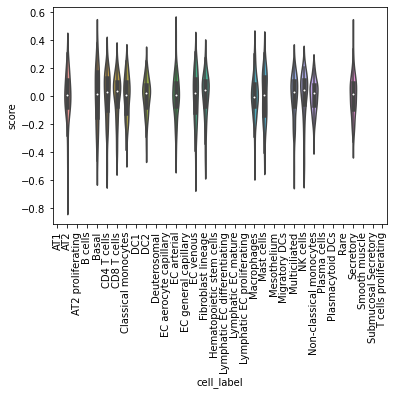

In [23]:
sb.violinplot(data=group,x="cell_label",y="score")
plt.xticks(rotation=90)

In [24]:
perc_5

{'AT2': -0.27411397319581854,
 'EC arterial': -0.24956823397990394,
 'Mast cells': -0.24978802634058897,
 'CD4 T cells': -0.27506709472713414,
 'CD8 T cells': -0.34531570143711365,
 'Classical monocytes': -0.23183958991928083,
 'NK cells': -0.397222063717157,
 'Non-classical monocytes': -0.18194829378596783,
 'Basal': -0.34739711448589655,
 'DC2': -0.22883848619686936,
 'EC venous': -0.2897026096568518,
 'Fibroblast lineage': -0.33213280999437994,
 'Macrophages': -0.22444010947843435,
 'Multiciliated': -0.26437930328523995,
 'Secretory': -0.23557907330226802}

In [25]:
group = group[group.cell_label.isin(transform.cell_label)]

In [26]:
group.cell_label.cat.remove_unused_categories(inplace=True)

Create the lookup table:

In [27]:
list_cat=group.cell_label.cat.categories.tolist()
list_cat.append("sample")
table= pd.DataFrame(data=[],columns=list_cat)

samp=group[group.cell_label==ct]["sample"]
table["sample"]=samp.to_numpy()
table.set_index("sample",verify_integrity=True,inplace=True)
for ct in group.cell_label.cat.categories:
    sub= group[group.cell_label==ct].score.to_numpy()
    sub_no_nan = (sub>=perc_5[ct]).astype(int)
    idx= np.argwhere(np.isnan(sub))
    sub_no_nan[idx]=-1
    table[ct]=sub_no_nan
    

In [28]:
table

,AT2,Basal,CD4 T cells,CD8 T cells,Classical monocytes,DC2,EC arterial,EC venous,Fibroblast lineage,Macrophages,Mast cells,Multiciliated,NK cells,Non-classical monocytes,Secretory
sample,,,,,,,,,,,,,,,
356C_0h,1,-1,1,1,1,1,-1,1,1,1,-1,1,1,1,-1
356C_12h,1,-1,1,1,1,1,-1,-1,1,1,-1,1,1,1,-1
356C_24h,1,-1,1,1,1,1,-1,1,1,1,-1,-1,1,1,-1
356C_72h,1,-1,1,1,1,1,-1,-1,1,1,-1,-1,1,1,-1
368C_0h,-1,-1,1,1,-1,-1,-1,-1,1,1,-1,-1,-1,-1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
distal 1a,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1
distal 2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
distal 3,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [29]:
table.to_csv(f"{workspace}/table_rejection.csv")

function to obtain custom threshold and plot distribution:

In [63]:
def get_threshold(celltype_list,weighted=True):
    celltype_list.append("sample")
    table = pd.read_csv(f"{workspace}/table_rejection.csv",index_col="sample",usecols=celltype_list)
    celltype_list.remove("sample")
    table = table.T
    count_list=[]
    for sample in table.columns:
        counts=table.value_counts(sample).reindex([0,1,-1], fill_value=0)
        weight = len(celltype_list)-counts[-1]
        if weight > 0:
            value= counts[0]/(counts[0]+counts[1])
            if weighted:
                count_list.extend([value]*weight)
            else:
                count_list.extend([value])
    return np.percentile(count_list,95)

Testing it out for some cell types:

0.3333333333333333

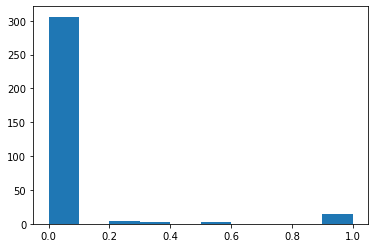

In [31]:
get_threshold(["Basal","DC2","EC arterial","Macrophages"])

0.5

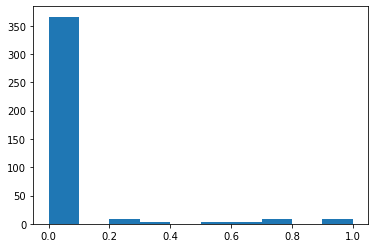

In [32]:
get_threshold(["Basal","DC2","EC arterial","Macrophages","CD4 T cells"])

Simulating weighted and unweighted thresholds for different number of cell types:

In [33]:
'''vals_weighted=[]
for i in range(2,len(table.columns)+1):
    values=[]
    for j in range(100):
        celltypes = list(np.random.choice(table.columns,i,replace=False))
        #print(celltypes)
        threshold = get_threshold(celltypes,weighted =True)
        values.append(threshold)
    vals_weighted.append((i,np.mean(values),np.std(values)))'''

'vals_weighted=[]\nfor i in range(2,len(table.columns)+1):\n    values=[]\n    for j in range(100):\n        celltypes = list(np.random.choice(table.columns,i,replace=False))\n        #print(celltypes)\n        threshold = get_threshold(celltypes,weighted =True)\n        values.append(threshold)\n    vals_weighted.append((i,np.mean(values),np.std(values)))'

In [34]:
'''vals_unweighted=[]
for i in range(2,len(table.columns)+1):
    values=[]
    for j in range(100):
        celltypes = list(np.random.choice(table.columns,i,replace=False))
        #print(celltypes)
        threshold = get_threshold(celltypes,weighted =False)
        values.append(threshold)
    vals_unweighted.append((i,np.mean(values),np.std(values)))'''

'vals_unweighted=[]\nfor i in range(2,len(table.columns)+1):\n    values=[]\n    for j in range(100):\n        celltypes = list(np.random.choice(table.columns,i,replace=False))\n        #print(celltypes)\n        threshold = get_threshold(celltypes,weighted =False)\n        values.append(threshold)\n    vals_unweighted.append((i,np.mean(values),np.std(values)))'

In [394]:
vals_weighted = pd.DataFrame(vals_weighted,columns=["n_celltypes","mean","std"])

In [395]:
vals_unweighted = pd.DataFrame(vals_unweighted,columns=["n_celltypes","mean","std"])

In [405]:
vals_weighted["expected_rej"] = vals_weighted["n_celltypes"]*vals_weighted["mean"]
vals_weighted

,n_celltypes,mean,std,expected_rej
0,2,0.499500,1.321930e-02,0.999000
1,3,0.494333,5.201335e-02,1.483000
2,4,0.473500,7.151515e-02,1.894000
3,5,0.458883,7.501594e-02,2.294417
4,6,0.443567,6.728630e-02,2.661400
5,7,0.428426,6.578524e-02,2.998983
6,8,0.413310,5.429298e-02,3.306481
7,9,0.418228,6.001770e-02,3.764055
8,10,0.396149,5.799629e-02,3.961492
9,11,0.404555,5.653930e-02,4.450105


In [406]:
vals_unweighted["expected_rej"] = vals_unweighted["n_celltypes"]*vals_unweighted["mean"]
vals_unweighted

,n_celltypes,mean,std,expected_rej
0,2,0.557750,1.520565e-01,1.115500
1,3,0.508167,9.253363e-02,1.524500
2,4,0.483792,9.980518e-02,1.935167
3,5,0.477467,7.035011e-02,2.387333
4,6,0.476050,6.912254e-02,2.856300
5,7,0.459264,5.965616e-02,3.214850
6,8,0.449989,6.294618e-02,3.599910
7,9,0.440657,5.994746e-02,3.965912
8,10,0.438451,5.783488e-02,4.384508
9,11,0.418684,5.444487e-02,4.605522


Text(0, 0.5, 'estimated_threshold')

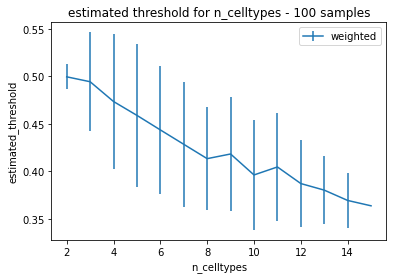

In [403]:
#plt.errorbar(x=range(2,len(table.columns)+1),y=vals_unweighted["mean"],yerr=vals_unweighted["std"],label="unweighted")
plt.errorbar(x=range(2,len(table.columns)+1),y=vals_weighted["mean"],yerr=vals_weighted["std"],label="weighted")

plt.legend()
plt.title("estimated threshold for n_celltypes - 100 samples")
plt.xlabel("n_celltypes")
plt.ylabel("estimated_threshold")

comparison of all cell types weighted vs unweighted:

0.3333333333333333

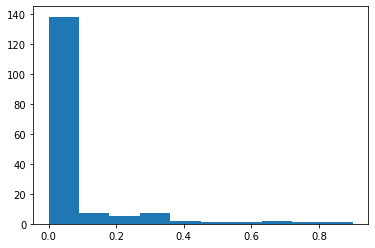

In [37]:
get_threshold(list(table.columns),weighted=False) #without

0.36363636363636365

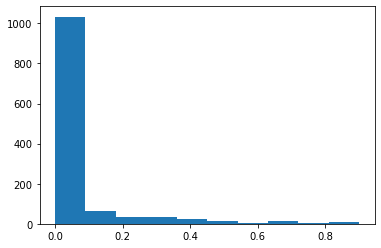

In [38]:
get_threshold(list(table.columns),weighted=True)

In [42]:
perc_5

{'AT2': -0.27411397319581854,
 'EC arterial': -0.24956823397990394,
 'Mast cells': -0.24978802634058897,
 'CD4 T cells': -0.27506709472713414,
 'CD8 T cells': -0.34531570143711365,
 'Classical monocytes': -0.23183958991928083,
 'NK cells': -0.397222063717157,
 'Non-classical monocytes': -0.18194829378596783,
 'Basal': -0.34739711448589655,
 'DC2': -0.22883848619686936,
 'EC venous': -0.2897026096568518,
 'Fibroblast lineage': -0.33213280999437994,
 'Macrophages': -0.22444010947843435,
 'Multiciliated': -0.26437930328523995,
 'Secretory': -0.23557907330226802}

Testing out for query samples + testing concept of uncertainty (samples with scores close to theshold more uncertain than strongly away from threshold) - Experimental concept not discussed for implementation yet.

In [89]:
for name in ["Duong_lungMAP_unpubl",
                "Eils_2020",
                "Gomperts_2021",
                "Janssen_2020",
                "Kaminski_2020_IPF",
                "Kaminski_2020_COPD",
                "Meyer_2021",
                "Meyer_Nikolic_2022",
                "Schiller_2020",
                "Schiller_2021",
                "Schultze_unpubl",
                "Shalek_2018",
                "Sheppard_2020_IPF",
                "Sheppard_2020_SSc_ILD",
                "Sims_2019",
                "Sun_2020",
                "Tata_unpubl",
                "Zhang_2021"]:
    print(name)
    acc=[]
    dataset = pd.read_csv(f'{workspace}\\{name}\\report.csv')
    #print(dataset)
    dataset = dataset[dataset.health_status=="disease"]
    for sample in dataset["sample"].astype("category").cat.categories:
        tmp = dataset[dataset["sample"]==sample]
        celltypes = list(tmp.cell_label)
        threshold = get_threshold(celltypes,weighted=True)
        tf = [tmp.loc[tmp.cell_label==ct,"mean"]<perc_5[ct] for ct in celltypes]
        tf = np.sum(tf)/len(tf)
        if tf < threshold:
            print(f'{sample} accepted: {np.round(tf-threshold,2)} to {np.round(threshold,2)} with uncertainty:{np.round(1/np.abs((tf-threshold)),2)}')
            acc.append(True)
        else:
            print(f'{sample} rejected: {np.round(tf-threshold,2)} to {np.round(threshold,2)} with uncertainty:{np.round(1/np.abs((tf-threshold)),2)}')  
            acc.append(False)
    print("SUMMARY")
    print(1-np.sum(acc)/len(acc))
    print(len(acc)-np.sum(acc))
    print()
    print()

Duong_lungMAP_unpubl
SUMMARY
nan
0.0


Eils_2020
SUMMARY
nan
0.0


Gomperts_2021
BG9_12 accepted: -0.17 to 0.5 with uncertainty:6.0


C:\Users\49176\AppData\Local\Temp\ipykernel_11276\1717188317.py:37: RuntimeWarning: invalid value encountered in double_scalars
  print(1-np.sum(acc)/len(acc))
C:\Users\49176\AppData\Local\Temp\ipykernel_11276\1717188317.py:37: RuntimeWarning: invalid value encountered in double_scalars
  print(1-np.sum(acc)/len(acc))


BG9_18 accepted: -0.5 to 0.5 with uncertainty:2.0
BG9_20 accepted: -0.16 to 0.41 with uncertainty:6.32
BG9_23 accepted: -0.5 to 0.5 with uncertainty:2.0
BG9_24 rejected: 0.75 to 0.25 with uncertainty:1.33
BG9_26 rejected: 0.17 to 0.5 with uncertainty:6.0
BG9_27 rejected: 0.0 to 0.5 with uncertainty:inf


C:\Users\49176\AppData\Local\Temp\ipykernel_11276\1717188317.py:34: RuntimeWarning: divide by zero encountered in double_scalars
  print(f'{sample} rejected: {np.round(tf-threshold,2)} to {np.round(threshold,2)} with uncertainty:{np.round(1/np.abs((tf-threshold)),2)}')


BG9_30 accepted: -0.17 to 0.5 with uncertainty:6.0
BG9_34 accepted: -0.17 to 0.5 with uncertainty:6.0
BG9_35 accepted: -0.5 to 0.5 with uncertainty:2.0
BG9_36 accepted: -0.5 to 0.5 with uncertainty:2.0
BG9_7 accepted: -0.5 to 0.5 with uncertainty:2.0
CF301018 accepted: -0.17 to 0.5 with uncertainty:6.0
KKCFFT32N accepted: -0.17 to 0.5 with uncertainty:6.0
KKD019N accepted: -0.5 to 0.5 with uncertainty:2.0
KKD020N accepted: -0.5 to 0.5 with uncertainty:2.0
KKD022N accepted: -0.08 to 0.33 with uncertainty:12.0
KKD023N accepted: -0.5 to 0.5 with uncertainty:2.0
KKD024N accepted: -0.75 to 0.75 with uncertainty:1.33
ND15656 accepted: -0.17 to 0.5 with uncertainty:6.0
ND16737 accepted: -0.5 to 0.5 with uncertainty:2.0
cf019 accepted: -0.5 to 0.5 with uncertainty:2.0
SUMMARY
0.13636363636363635
3


Janssen_2020
SUMMARY
nan
0.0


Kaminski_2020_IPF


...

Polyp16BEPI rejected: 0.0 to 0.5 with uncertainty:inf
Polyp17AEPI rejected: 0.0 to 0.5 with uncertainty:inf
Polyp17BEPI accepted: -0.33 to 0.33 with uncertainty:3.0
Polyp19AEPI rejected: 0.01 to 0.39 with uncertainty:75.0
Polyp19BEPI accepted: -0.22 to 0.33 with uncertainty:4.5
Polyp1TOT accepted: -0.4 to 0.4 with uncertainty:2.5
Polyp2TOT accepted: -0.5 to 0.5 with uncertainty:2.0
Polyp3TOT accepted: -0.4 to 0.4 with uncertainty:2.5
Polyp4TOT accepted: -0.36 to 0.5 with uncertainty:2.8
Polyp5TOT accepted: -0.33 to 0.33 with uncertainty:3.0
Polyp6ATOT accepted: -0.33 to 0.5 with uncertainty:3.0
Polyp6BTOT accepted: -0.5 to 0.5 with uncertainty:2.0
Polyp7TOT accepted: -0.5 to 0.5 with uncertainty:2.0
Polyp8TOT accepted: -0.5 to 0.5 with uncertainty:2.0
Polyp9TOT accepted: -0.4 to 0.4 with uncertainty:2.5
SUMMARY
0.16666666666666663
3


Sheppard_2020_IPF
IPF1_Lin accepted: -0.5 to 0.5 with uncertainty:2.0
IPF2_All accepted: -0.38 to 0.38 with uncertainty:2.6
IPF2_Lin accepted: -0.5 to 0.

C:\Users\49176\AppData\Local\Temp\ipykernel_11276\1717188317.py:34: RuntimeWarning: divide by zero encountered in double_scalars
  print(f'{sample} rejected: {np.round(tf-threshold,2)} to {np.round(threshold,2)} with uncertainty:{np.round(1/np.abs((tf-threshold)),2)}')


SCD2_All accepted: -0.06 to 0.33 with uncertainty:16.5
SCD2_Lin rejected: 0.0 to 0.5 with uncertainty:inf
SUMMARY
0.5
2


Sims_2019
PP002 accepted: -0.5 to 0.5 with uncertainty:2.0
PP010 accepted: -0.5 to 0.5 with uncertainty:2.0
SUMMARY
0.0
0


Sun_2020
SUMMARY
nan
0.0


Tata_unpubl
SUMMARY
nan
0.0


Zhang_2021
M1 rejected: 0.56 to 0.33 with uncertainty:1.8


C:\Users\49176\AppData\Local\Temp\ipykernel_11276\1717188317.py:37: RuntimeWarning: invalid value encountered in double_scalars
  print(1-np.sum(acc)/len(acc))
C:\Users\49176\AppData\Local\Temp\ipykernel_11276\1717188317.py:37: RuntimeWarning: invalid value encountered in double_scalars
  print(1-np.sum(acc)/len(acc))


M2 rejected: 0.5 to 0.38 with uncertainty:2.0
M3 rejected: 0.6 to 0.4 with uncertainty:1.67
S1 rejected: 0.22 to 0.33 with uncertainty:4.5
S2 rejected: 0.39 to 0.33 with uncertainty:2.54
S3 rejected: 0.42 to 0.33 with uncertainty:2.4
S4 rejected: 0.56 to 0.33 with uncertainty:1.8
S5 rejected: 0.42 to 0.33 with uncertainty:2.4
S6 rejected: 0.54 to 0.33 with uncertainty:1.85
SUMMARY
1.0
9


